# Human vs. AI Text: Model B Analysis (Report Sections 2–4)

Experiments on the final Model B (text model + style model blend, `w = 0.4`) for the report:

1. **Learning curve (Q2):** Model B trained on 500 to 8,000 passages.
2. **Unlabeled data (Q3):** confidence-based self-training with `unlabeled.csv`.
3. **Error analysis (Q4):** length bins, a line-break subgroup, and the most confident mistakes.

Same split, settings and seed as `02_modelB.ipynb`. All results go to `outputs/`. Runtime about 5 minutes.

## 1. Setup

Same imports, paths and model definitions as `02_modelB.ipynb`, with the hyperparameters chosen there.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
TEXT_C = 10                 # chosen by grid search in 02_modelB.ipynb
STYLE_LR, STYLE_DEPTH = 0.1, None
STYLE_WEIGHT = 0.4          # blend weight chosen from out-of-fold predictions in 02_modelB.ipynb

PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "train.csv").is_file() and (folder / "data" / "test.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find data/train.csv and data/test.csv.")
DATA_DIR, OUTPUT_DIR = PROJECT_ROOT / "data", PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)


def normalize_whitespace(texts):
    return texts.fillna("").str.replace(r"\s+", " ", regex=True).str.strip()


def style_features(texts):
    texts = pd.Series(texts)
    words = texts.str.split()
    n_words = words.str.len().clip(lower=1)
    sent_lens = texts.str.split(r"(?<=[.!?])\s+").apply(lambda sents: [len(s.split()) for s in sents if s])
    return pd.DataFrame({
        "avg_word_len": texts.str.replace(" ", "").str.len() / n_words,
        "avg_sent_len": sent_lens.apply(np.mean),
        "sent_len_std": sent_lens.apply(np.std),
        "vocab_richness": words.apply(lambda w: len({x.lower() for x in w})) / n_words,
        "comma_rate": texts.str.count(",") / n_words,
        "semicolon_rate": texts.str.count(";") / n_words,
        "exclaim_rate": texts.str.count("!") / n_words,
        "question_rate": texts.str.count(r"\?") / n_words,
        "quote_rate": texts.str.count('"') / n_words,
        "digit_rate": texts.str.count(r"\d") / n_words,
        "upper_rate": texts.str.count(r"[A-Z]") / n_words,
        "lowercase_i": texts.str.count(r"\bi\b") / n_words,
    }).fillna(0)


def make_text_model():
    features = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=100000,
                                 sublinear_tf=True)),
    ])
    return Pipeline([("tfidf", features),
                     ("classifier", LogisticRegression(C=TEXT_C, max_iter=2000, random_state=RANDOM_STATE))])


def make_style_model():
    return Pipeline([("style", FunctionTransformer(style_features)),
                     ("classifier", HistGradientBoostingClassifier(learning_rate=STYLE_LR, max_depth=STYLE_DEPTH,
                                                                   random_state=RANDOM_STATE))])


def fit_model_b(texts, labels):
    """Fit both halves of Model B and return them as a pair."""
    return make_text_model().fit(texts, labels), make_style_model().fit(texts, labels)


def predict_model_b(models, texts):
    text_model, style_model = models
    return (STYLE_WEIGHT * style_model.predict_proba(texts)[:, 1]
            + (1 - STYLE_WEIGHT) * text_model.predict_proba(texts)[:, 1])

## 2. Load data and reuse the split

In [2]:
raw_train = pd.read_csv(DATA_DIR / "train.csv")
unlabeled = pd.read_csv(DATA_DIR / "unlabeled.csv")

train = raw_train.copy()
train["text"] = normalize_whitespace(train["text"])
unlabeled["text"] = normalize_whitespace(unlabeled["text"])

train_idx, val_idx = train_test_split(np.arange(len(train)), test_size=2000,
                                      random_state=RANDOM_STATE, stratify=train["label"])
train_split, val_split = train.iloc[train_idx], train.iloc[val_idx]
ids_file = OUTPUT_DIR / "validation_ids.csv"
if ids_file.is_file():
    assert set(pd.read_csv(ids_file)["id"]) == set(val_split["id"]), "Split differs from the baseline!"

X_train, y_train = train_split["text"].reset_index(drop=True), train_split["label"].to_numpy()
X_val, y_val = val_split["text"].reset_index(drop=True), val_split["label"].to_numpy()

# The unlabeled passages must not overlap with any labeled passage (no leakage)
assert not set(unlabeled["text"]) & set(train["text"]), "Unlabeled text overlaps labeled text!"
print("Train:", len(X_train), "| Validation:", len(X_val), "| Unlabeled:", len(unlabeled))

Train: 8000 | Validation: 2000 | Unlabeled: 3000


## 3. Learning curve (Q2)

Model B with fixed settings, trained on stratified subsets of the 8,000 training passages. Training AUROC is measured on the rows each model was trained on; validation AUROC always uses the same 2,000 passages.

In [3]:
curve = []
for n in [500, 1000, 2000, 5000, 8000]:
    if n < len(X_train):
        rows, _ = train_test_split(np.arange(len(X_train)), train_size=n,
                                   random_state=RANDOM_STATE, stratify=y_train)
    else:
        rows = np.arange(len(X_train))
    start = time.perf_counter()
    models = fit_model_b(X_train.iloc[rows], y_train[rows])
    curve.append({"training_rows": n,
                  "train_auc": roc_auc_score(y_train[rows], predict_model_b(models, X_train.iloc[rows])),
                  "val_auc": roc_auc_score(y_val, predict_model_b(models, X_val)),
                  "seconds": time.perf_counter() - start})
    print(f"{n:>5} rows: val AUROC {curve[-1]['val_auc']:.4f}")

curve_df = pd.DataFrame(curve)
curve_df["gap"] = curve_df["train_auc"] - curve_df["val_auc"]
display(curve_df.round(4))

  500 rows: val AUROC 0.9024


 1000 rows: val AUROC 0.9328


 2000 rows: val AUROC 0.9466


 5000 rows: val AUROC 0.9638


 8000 rows: val AUROC 0.9700


,training_rows,train_auc,val_auc,seconds,gap
0,500,1.0,0.9024,4.4585,0.0976
1,1000,1.0,0.9328,6.2673,0.0672
2,2000,1.0,0.9466,10.5881,0.0534
3,5000,1.0,0.9638,21.2828,0.0362
4,8000,1.0,0.9700,34.5934,0.0300


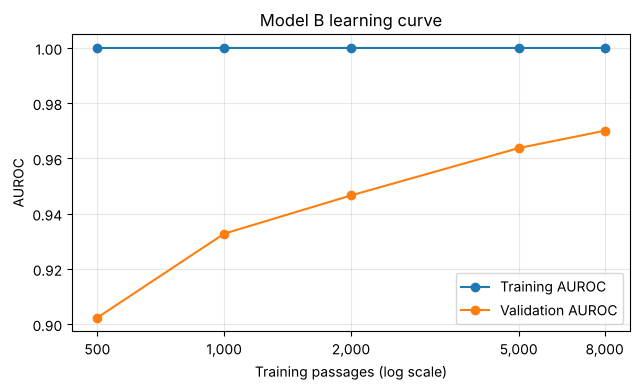

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(curve_df["training_rows"], curve_df["train_auc"], marker="o", label="Training AUROC")
ax.plot(curve_df["training_rows"], curve_df["val_auc"], marker="o", label="Validation AUROC")
ax.set_xscale("log"); ax.minorticks_off()
ax.set_xticks(curve_df["training_rows"]); ax.set_xticklabels([f"{n:,}" for n in curve_df["training_rows"]])
ax.set_xlabel("Training passages (log scale)"); ax.set_ylabel("AUROC")
ax.set_title("Model B learning curve"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "modelB_learning_curve.png", dpi=200)
plt.show()

## 4. Learning from unlabeled data (Q3): self-training

1. Fit Model B on the 8,000 labeled training passages.
2. Predict the 3,000 unlabeled passages.
3. Keep only confident predictions as pseudo-labels: P(AI) ≥ 0.9 → AI, P(AI) ≤ 0.1 → human. The thresholds are fixed in advance, not tuned on validation.
4. Refit Model B on the labeled passages plus the pseudo-labeled ones, and score the same validation set.

The validation passages are never used for training or pseudo-labeling.

In [5]:
HIGH, LOW = 0.9, 0.1

start = time.perf_counter()
supervised = fit_model_b(X_train, y_train)
supervised_time = time.perf_counter() - start
p_val_sup = predict_model_b(supervised, X_val)
p_unl = predict_model_b(supervised, unlabeled["text"])

confident = (p_unl >= HIGH) | (p_unl <= LOW)
pseudo_text = unlabeled["text"][confident].reset_index(drop=True)
pseudo_label = (p_unl[confident] >= HIGH).astype(int)
print(f"Pseudo-labeled {confident.sum()} of {len(unlabeled)} unlabeled passages "
      f"({pseudo_label.sum()} AI, {(1 - pseudo_label).sum()} human)")

start = time.perf_counter()
self_trained = fit_model_b(pd.concat([X_train, pseudo_text], ignore_index=True),
                           np.concatenate([y_train, pseudo_label]))
self_trained_time = time.perf_counter() - start
p_val_self = predict_model_b(self_trained, X_val)

Pseudo-labeled 904 of 3000 unlabeled passages (500 AI, 404 human)


In [6]:
# How noisy would pseudo-labels at these thresholds be? Apply the same rule to the labeled
# validation set (measurement only; nothing here is used for training or tuning).
val_conf = (p_val_sup >= HIGH) | (p_val_sup <= LOW)
pseudo_accuracy = ((p_val_sup[val_conf] >= HIGH).astype(int) == y_val[val_conf]).mean()

unlabeled_results = pd.DataFrame([
    {"method": "Supervised only (8,000 labeled)", "train_rows": len(X_train),
     "val_auc": roc_auc_score(y_val, p_val_sup), "seconds": supervised_time},
    {"method": f"Self-training (+{confident.sum()} pseudo-labeled)", "train_rows": len(X_train) + confident.sum(),
     "val_auc": roc_auc_score(y_val, p_val_self), "seconds": self_trained_time},
])
display(unlabeled_results.round(4))
print(f"Share of validation passages that pass the confidence rule: {val_conf.mean():.1%}")
print(f"Accuracy of those confident predictions (estimated pseudo-label accuracy): {pseudo_accuracy:.1%}")

,method,train_rows,val_auc,seconds
0,"Supervised only (8,000 labeled)",8000,0.9700,18.2589
1,Self-training (+904 pseudo-labeled),8904,0.9685,19.5868


Share of validation passages that pass the confidence rule: 33.9%
Accuracy of those confident predictions (estimated pseudo-label accuracy): 99.9%


## 5. Error analysis (Q4)

Uses the supervised Model B from Section 4 (identical to `02_modelB.ipynb`). Threshold 0.5. A false positive is a human passage predicted AI; a false negative is an AI passage predicted human.

### 5.1 Subgroups: length bins and original line breaks

In [7]:
text_model, style_model = supervised
val = val_split[["id", "label"]].reset_index(drop=True).copy()
val["p"] = p_val_sup
val["p_text"] = text_model.predict_proba(X_val)[:, 1]
val["p_style"] = style_model.predict_proba(X_val)[:, 1]
val["words"] = X_val.str.split().str.len()
val["raw_text"] = raw_train.set_index("id").loc[val["id"], "text"].to_numpy()
val["had_line_breaks"] = val["raw_text"].str.contains("\n")
val["length_bin"] = pd.cut(val["words"], [0, 149, 249, 400],
                           labels=["Short: 75-149 words", "Medium: 150-249 words", "Long: 250-350 words"])
val["fp"] = (val["label"] == 0) & (val["p"] >= 0.5)
val["fn"] = (val["label"] == 1) & (val["p"] < 0.5)


def subgroup_table(column):
    rows = []
    for name, g in val.groupby(column, observed=True):
        rows.append({"subgroup": f"{column} = {name}", "count": len(g),
                     "val_auc": roc_auc_score(g["label"], g["p"]),
                     "text_model_auc": roc_auc_score(g["label"], g["p_text"]),
                     "style_model_auc": roc_auc_score(g["label"], g["p_style"]),
                     "fn_rate_among_ai": g.loc[g["label"] == 1, "fn"].mean(),
                     "fp_rate_among_human": g.loc[g["label"] == 0, "fp"].mean()})
    return pd.DataFrame(rows)


subgroups = pd.concat([subgroup_table("length_bin"), subgroup_table("had_line_breaks")], ignore_index=True)
display(subgroups.round(4))

,subgroup,count,val_auc,text_model_auc,style_model_auc,fn_rate_among_ai,fp_rate_among_human
0,length_bin = Short: 75-149 words,404,0.9518,0.9256,0.8827,0.1575,0.0867
1,length_bin = Medium: 150-249 words,1055,0.9726,0.9553,0.8993,0.1149,0.0516
2,length_bin = Long: 250-350 words,541,0.9785,0.9716,0.8754,0.1029,0.0261
3,had_line_breaks = False,602,0.9826,0.9559,0.9536,0.0677,0.0595
4,had_line_breaks = True,1398,0.9652,0.9527,0.8586,0.1417,0.0467


### 5.2 Most confident mistakes

The first 300 characters of each passage are shown for reading; the report gives IDs and short hypotheses only.

In [8]:
cols = ["id", "p", "p_text", "p_style", "words"]
false_pos = val[val["fp"]].sort_values("p", ascending=False)
false_neg = val[val["fn"]].sort_values("p")
print(f"False positives: {len(false_pos)} | False negatives: {len(false_neg)}")

for title, frame in [("FALSE POSITIVES (human predicted AI)", false_pos), ("FALSE NEGATIVES (AI predicted human)", false_neg)]:
    print(f"\n===== {title}")
    for _, r in frame.head(8).iterrows():
        print(f"\nID {r['id']} | P(AI) {r['p']:.3f} | text {r['p_text']:.3f} | style {r['p_style']:.3f} | {r['words']} words")
        print(r["raw_text"][:300].replace("\n", " / "))

False positives: 51 | False negatives: 122

===== FALSE POSITIVES (human predicted AI)

ID 3660 | P(AI) 0.803 | text 0.693 | style 0.969 | 207 words
Hector MacLean may refer to: Clan Chiefs / Many chiefs of Clan Maclean have been called Hector or Eachann, including: /  Red Hector of the Battles Maclean (1368–1411), 6th Clan Chief, killed at the Battle of Harlaw, also known as "Red Hector" /  Hector Odhar Maclean (?–1513), 9th Clan Chief, also known as

ID 7562 | P(AI) 0.748 | text 0.976 | style 0.406 | 280 words
1 c. sliced ripe banana / 1/3 c. buttermilk / 1 1/2 Tbsp. oil / 1 1/2 Tbsp. honey / 1 1/3 c. Robin Hood Best For Bread homestyle white flour / 2/3 c. Robin Hood Best For Bread whole wheat flour / 1 tsp salt / 1 1/4 tsp Robin Hood/SAF Perfect Rise Gourmet Yeast / 1 1/2 c. sliced ripe banana / 1/2 c. buttermilk / 2 Tbsp.

ID 3326 | P(AI) 0.745 | text 0.635 | style 0.911 | 114 words
The Academy Award winning war epic Braveheart is an extraordinary film that set a new bar for the g

### 5.3 Do the two halves of Model B fail on the same passages?

In [9]:
def agreement(errors, wrong_text, wrong_style):
    return {"errors": len(errors), "both_wrong": (wrong_text & wrong_style).mean(),
            "only_text_wrong": (wrong_text & ~wrong_style).mean(),
            "only_style_wrong": (~wrong_text & wrong_style).mean()}

agree = pd.DataFrame({
    "false positives": agreement(false_pos, false_pos["p_text"] >= 0.5, false_pos["p_style"] >= 0.5),
    "false negatives": agreement(false_neg, false_neg["p_text"] < 0.5, false_neg["p_style"] < 0.5),
}).T
display(agree.round(3))

,errors,both_wrong,only_text_wrong,only_style_wrong
false positives,51.0,0.255,0.373,0.373
false negatives,122.0,0.492,0.344,0.164


### 5.4 Numbers used in the report's improvement section (Q5) and error hypotheses

In [10]:
# Q5: text model alone vs. full Model B, on the same validation set
q5 = []
for name, p in [("Text model only", val["p_text"]), ("Model B (text + style blend)", val["p"])]:
    pred = p >= 0.5
    short = val["length_bin"] == "Short: 75-149 words"
    q5.append({"configuration": name, "val_auc": roc_auc_score(y_val, p), "accuracy": (pred == y_val).mean(),
               "false_positives": int(((y_val == 0) & pred).sum()), "false_negatives": int(((y_val == 1) & ~pred).sum()),
               "short_passage_auc": roc_auc_score(y_val[short], p[short])})
q5_df = pd.DataFrame(q5)
display(q5_df.round(4))
print("Rank correlation between text and style model predictions:",
      round(val[["p_text", "p_style"]].corr(method="spearman").iloc[0, 1], 3))

# Checks behind two error hypotheses (keyword heuristics on the 10,000 labeled passages)
recipe = raw_train["text"].str.contains(r"\b(?:tsp|tbsp|teaspoons?|tablespoons?)\b", case=False)
news = (raw_train["text"].str.contains(r"\b(?:said|told reporters|according to)\b")
        & raw_train["text"].str.contains(r"\b(?:Mr|Ms|chief executive|government|minister|shares|club|season)\b"))
print(f"Recipe-like passages: {recipe.sum()}, share AI {raw_train.loc[recipe, 'label'].mean():.1%}")
print(f"News-like passages: {news.sum()}, share AI {raw_train.loc[news, 'label'].mean():.1%}")

,configuration,val_auc,accuracy,false_positives,false_negatives,short_passage_auc
0,Text model only,0.9526,0.8865,75,152,0.9256
1,Model B (text + style blend),0.9700,0.9135,51,122,0.9518


Rank correlation between text and style model predictions: 0.634


Recipe-like passages: 1690, share AI 47.0%
News-like passages: 505, share AI 40.8%


## 6. Save results

In [11]:
curve_df.to_csv(OUTPUT_DIR / "modelB_learning_curve.csv", index=False)
unlabeled_results.to_csv(OUTPUT_DIR / "modelB_unlabeled_results.csv", index=False)
subgroups.to_csv(OUTPUT_DIR / "modelB_subgroups.csv", index=False)
pd.concat([false_pos.head(10).assign(error="FP"), false_neg.head(10).assign(error="FN")])[
    ["id", "error", "p", "p_text", "p_style", "words"]].to_csv(OUTPUT_DIR / "modelB_top_errors.csv", index=False)
print("Saved learning curve, unlabeled results, subgroups and top errors to", OUTPUT_DIR.relative_to(PROJECT_ROOT))

Saved learning curve, unlabeled results, subgroups and top errors to outputs
